# Gabarito — Teorema de Tales

Este notebook traz a resolução comentada dos exercícios de [`0414a_teorema_de_tales.ipynb`](0414a_teorema_de_tales.ipynb).

⚠️ **Antes de olhar aqui:** tente resolver os exercícios sozinho no notebook original e use as células de verificação (`assert`) para conferir sua resposta. Volte a este gabarito só depois de tentar — ou se travar de verdade em algum passo.

In [ ]:
# Imports necessários para os exercícios abaixo
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Arc, Circle, Polygon, Wedge

# Paleta de cores Nord
NORD_FUNDO = "#2E3440"
NORD_PAINEL = "#3B4252"
NORD_LINHA = "#4C566A"
NORD_TEXTO = "#ECEFF4"
NORD_TEXTO_SEC = "#D8DEE9"
COR_PONTO = "#88C0D0"
COR_DESTAQUE = "#A3BE8C"
COR_ALERTA = "#BF616A"
COR_SECUNDARIA = "#81A1C1"
COR_EXTRA = "#B48EAD"
COR_AVISO = "#EBCB8B"


def estilizar_eixo(ax) -> None:
    """Aplica o estilo Nord padrão a um eixo do matplotlib."""
    ax.set_facecolor(NORD_FUNDO)
    ax.tick_params(colors=NORD_TEXTO_SEC)
    for spine in ax.spines.values():
        spine.set_color(NORD_LINHA)
    ax.grid(color=NORD_LINHA, linewidth=0.5, alpha=0.5)


# Ferramentas do notebook principal (reconstruídas aqui).

def preparar_eixo(ax, pontos, margem: float = 0.8) -> None:
    """Deixa o eixo pronto para desenhos de geometria (estilo Nord, sem grade, sem números,
    escala igual) e enquadra todos os `pontos` com uma margem em volta."""
    estilizar_eixo(ax)
    ax.grid(False)
    xs = [p[0] for p in pontos]
    ys = [p[1] for p in pontos]
    ax.set_xlim(min(xs) - margem, max(xs) + margem)
    ax.set_ylim(min(ys) - margem, max(ys) + margem)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])


def direcao(angulo_graus: float) -> np.ndarray:
    """Vetor de tamanho 1 apontando na direção dada, em graus, a partir da horizontal (sentido anti-horário).

    (cos e sin vêm da Trigonometria, módulo 05; aqui só servem para apontar na direção certa.)
    """
    rad = math.radians(angulo_graus)
    return np.array([math.cos(rad), math.sin(rad)])


def direcao_de(origem, destino) -> float:
    """Direção, em graus, em que `destino` está quando visto de `origem`."""
    return math.degrees(math.atan2(destino[1] - origem[1], destino[0] - origem[0]))


def medir_angulo(vertice, P, Q) -> float:
    """Transferidor digital: medida, em graus, do ângulo com vértice em `vertice`
    formado pelas semirretas que passam por P e por Q (resultado entre 0° e 180°)."""
    u = np.subtract(P, vertice)
    v = np.subtract(Q, vertice)
    cosseno = np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))
    return math.degrees(math.acos(np.clip(cosseno, -1, 1)))


def cruzamento(P, inclinacao_1: float, Q, inclinacao_2: float):
    """Ponto em que a reta que passa por P (com a inclinação `inclinacao_1`, em graus) cruza a reta
    que passa por Q (com a inclinação `inclinacao_2`). Devolve None se as duas retas tiverem a mesma
    direção, porque aí elas não se cruzam num ponto só.

    Por trás, é um sistema linear 2×2 (módulo 03): P + t·u = Q + k·v, com incógnitas t e k.
    """
    matriz = np.column_stack([direcao(inclinacao_1), -direcao(inclinacao_2)])
    if abs(np.linalg.det(matriz)) < 1e-12:
        return None
    t, _ = np.linalg.solve(matriz, np.subtract(Q, P))
    return np.array(P, dtype=float) + t * direcao(inclinacao_1)


def ponto_medio(P, Q) -> np.ndarray:
    """Ponto médio do segmento PQ: a média das coordenadas (0402a)."""
    return (np.asarray(P, dtype=float) + np.asarray(Q, dtype=float)) / 2


def iguais(x: float, y: float) -> bool:
    """Compara duas medidas com uma tolerância pequena (as contas com float têm arredondamentos)."""
    return math.isclose(x, y, rel_tol=1e-9, abs_tol=1e-6)


def desenhar_ponto(ax, p, nome: str = "", cor: str = COR_AVISO, deslocamento=(0.12, 0.15),
                   tamanho_fonte: int = 13) -> None:
    """Desenha um ponto com seu nome (letra maiúscula) ao lado."""
    ax.plot(*p, "o", color=cor, markersize=7, zorder=6)
    if nome:
        ax.text(p[0] + deslocamento[0], p[1] + deslocamento[1], nome, color=NORD_TEXTO, fontsize=tamanho_fonte,
                fontweight="bold", zorder=7)


def desenhar_reta(ax, P, Q, cor: str = COR_SECUNDARIA, estilo: str = "-", largura: float = 2.0,
                  alpha: float = 0.9) -> None:
    """Desenha a reta inteira que passa por P e por Q (até a borda do gráfico)."""
    ax.axline(tuple(np.asarray(P, dtype=float)), tuple(np.asarray(Q, dtype=float)), color=cor,
              linestyle=estilo, lw=largura, alpha=alpha, zorder=2)


def desenhar_setor(ax, vertice, inicio: float, abertura: float, raio: float = 0.5, cor: str = COR_PONTO,
                   rotulo: str | None = None, marcar_reto: bool = True, raio_rotulo: float | None = None,
                   tamanho_fonte: int = 11) -> None:
    """Pinta o ângulo com vértice em `vertice` que começa na direção `inicio` e gira `abertura`
    graus no sentido anti-horário. O ângulo reto ganha o quadradinho no lugar do arco."""
    v = np.array(vertice, dtype=float)
    if marcar_reto and math.isclose(abertura, 90, abs_tol=1e-6):
        lado = 0.6 * raio
        canto = [v, v + lado * direcao(inicio), v + lado * (direcao(inicio) + direcao(inicio + 90)),
                 v + lado * direcao(inicio + 90)]
        ax.add_patch(Polygon(canto, closed=True, facecolor=cor, alpha=0.35, edgecolor=cor, lw=2))
    else:
        ax.add_patch(Wedge(v, raio, inicio, inicio + abertura, facecolor=cor, alpha=0.3, edgecolor="none"))
        ax.add_patch(Arc(v, 2 * raio, 2 * raio, theta1=inicio, theta2=inicio + abertura, color=cor, lw=2))
    if rotulo:
        distancia_rotulo = 1.6 * raio if raio_rotulo is None else raio_rotulo
        posicao = v + distancia_rotulo * direcao(inicio + abertura / 2)
        ax.text(*posicao, rotulo, color=cor, fontsize=tamanho_fonte, ha="center", va="center", fontweight="bold")


def desenhar_arco(ax, vertice, p, q, **opcoes) -> None:
    """Marca o ângulo de vértice `vertice` formado pelas semirretas que passam por p e por q
    (sempre a abertura menor, entre 0° e 180°). Aceita as mesmas opções de `desenhar_setor`."""
    inicio = direcao_de(vertice, p) % 360
    abertura = (direcao_de(vertice, q) - inicio) % 360
    if abertura > 180:
        inicio, abertura = direcao_de(vertice, q) % 360, 360 - abertura
    desenhar_setor(ax, vertice, inicio, abertura, **opcoes)


def marcar_congruentes(ax, P, Q, tracos: int = 1, cor: str = NORD_TEXTO, tamanho: float = 0.16) -> None:
    """Tracinhos no meio do segmento PQ: a marca de segmentos congruentes (0402a)."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    u = (Q - P) / np.linalg.norm(Q - P)
    normal = np.array([-u[1], u[0]])
    meio = (P + Q) / 2
    for k in range(tracos):
        centro_traco = meio + (k - (tracos - 1) / 2) * 0.12 * u
        ax.plot(*zip(centro_traco - tamanho * normal, centro_traco + tamanho * normal), color=cor, lw=2,
                zorder=6)


def rotular_fora(ax, P, texto: str, centro, cor: str = NORD_TEXTO, distancia: float = 0.35,
                 tamanho: int = 12) -> None:
    """Escreve `texto` perto do ponto P, afastado do `centro` (para não ficar em cima da figura)."""
    P = np.asarray(P, dtype=float)
    afastar = P - np.asarray(centro, dtype=float)
    afastar = afastar / np.linalg.norm(afastar) if np.linalg.norm(afastar) > 0 else np.array([0.0, 1.0])
    ax.text(*(P + distancia * afastar), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=7)


def escrever_checklist(ax, itens, titulo: str = "") -> None:
    """Painel de texto com uma linha por item (texto, ok): ✓ verde quando vale, ✗ vermelho quando não (0410a)."""
    ax.set_facecolor(NORD_FUNDO)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    if titulo:
        ax.text(0.0, 0.97, titulo, color=NORD_TEXTO, fontsize=12, fontweight="bold", va="top")
    passo = min(0.13, 0.85 / max(len(itens), 1))
    for k, (texto, ok) in enumerate(itens):
        ax.text(0.0, 0.84 - k * passo, f"{'✓' if ok else '✗'}  {texto}", color=COR_DESTAQUE if ok else COR_ALERTA,
                fontsize=11, va="top")


def desenhar_circunferencia(ax, O, r: float, cor: str = COR_PONTO, estilo: str = "-",
                            largura: float = 2.5, preencher: bool = False, opacidade: float = 0.15) -> None:
    """Desenha a circunferência de centro O e raio r (a linha). Com `preencher=True`, pinta também a
    região interna: o círculo (0412a)."""
    O = tuple(np.asarray(O, dtype=float))
    if preencher:
        ax.add_patch(Circle(O, r, facecolor=cor, alpha=opacidade, edgecolor="none", zorder=1))
    ax.add_patch(Circle(O, r, fill=False, edgecolor=cor, lw=largura, linestyle=estilo, zorder=3))


# Ferramentas novas deste notebook: cores fixas para o feixe, as transversais e os pares de segmentos
COR_PARALELA = COR_SECUNDARIA  # as retas do feixe de paralelas
COR_TRANSVERSAL = NORD_TEXTO_SEC  # as transversais
COR_AUXILIAR = NORD_LINHA  # traços auxiliares de construção
COR_BISSETRIZ = "#D08770"  # bissetrizes (interna e externa)
# Um par de cores por segmento correspondente: o 1º segmento das duas transversais é amarelo, o 2º é verde...
CORES_PARES = [COR_AVISO, COR_DESTAQUE, COR_EXTRA, COR_ALERTA, COR_PONTO, "#D08770"]


def produto_vetorial(u, v) -> float:
    """Produto vetorial de dois vetores do plano, u_x·v_y − u_y·v_x: a "multiplicação cruzada" de 0401a.
    Ele é zero exatamente quando u e v têm a mesma direção."""
    return float(u[0] * v[1] - u[1] * v[0])


def sao_paralelos(P, Q, R, S) -> bool:
    """True se as retas PQ e RS são paralelas (ou coincidentes): as direções Q − P e S − R têm produto
    vetorial (praticamente) zero."""
    u, v = np.subtract(Q, P), np.subtract(S, R)
    return abs(produto_vetorial(u, v)) <= 1e-9 * np.linalg.norm(u) * np.linalg.norm(v)


def cruzamento_das_retas(A, B, C, D):
    """Ponto em que a reta AB cruza a reta CD (None se forem paralelas)."""
    return cruzamento(A, direcao_de(A, B), C, direcao_de(C, D))


def pontos_na_transversal(origem, inclinacao: float, distancias) -> list[np.ndarray]:
    """Pontos sobre a reta que sai de `origem` com a inclinação dada, separados pelas `distancias`
    sucessivas: o primeiro ponto é a própria origem."""
    posicoes = np.concatenate([[0.0], np.cumsum(distancias)])
    return [np.asarray(origem, dtype=float) + s * direcao(inclinacao) for s in posicoes]


def cortes_na_transversal(pontos, inclinacao_feixe: float, ponto_t2, inclinacao_t2: float) -> list[np.ndarray]:
    """Traça, por cada um dos `pontos` (da primeira transversal), uma reta do feixe (todas com a MESMA
    inclinação, ou seja, paralelas) e devolve onde cada uma corta a segunda transversal, que passa por
    `ponto_t2` com a inclinação `inclinacao_t2`."""
    return [cruzamento(P, inclinacao_feixe, ponto_t2, inclinacao_t2) for P in pontos]


def desenhar_segmento(ax, P, Q, cor: str = NORD_TEXTO, largura: float = 3.0, estilo: str = "-",
                      alpha: float = 1.0, zorder: int = 5) -> None:
    """Desenha o segmento PQ (só o pedaço entre P e Q)."""
    ax.plot(*zip(P, Q), color=cor, lw=largura, linestyle=estilo, alpha=alpha, zorder=zorder,
            solid_capstyle="round")


def rotular_segmento(ax, P, Q, texto: str, cor: str = NORD_TEXTO, distancia: float = 0.35, longe_de=None,
                     tamanho: int = 11) -> None:
    """Escreve `texto` ao lado do meio do segmento PQ, afastado `distancia` na direção perpendicular a ele.
    Se `longe_de` for um ponto, o texto vai para o lado do segmento oposto a esse ponto."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    u = (Q - P) / np.linalg.norm(Q - P)
    normal = np.array([-u[1], u[0]])
    meio = (P + Q) / 2
    if longe_de is not None and np.dot(meio - np.asarray(longe_de, dtype=float), normal) < 0:
        normal = -normal
    ax.text(*(meio + distancia * normal), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=7)


def desenhar_feixe(ax, pontos_t, pontos_t2, nomes: str = "ABCDEF", rotular_medidas: bool = True,
                   tamanho: int = 13) -> None:
    """Desenha um feixe de paralelas (uma reta por par de pontos correspondentes), as duas transversais e os
    segmentos correspondentes, cada par com a sua cor. Os pontos da 1ª transversal se chamam A, B, C, ... e
    os da 2ª, A', B', C', ..."""
    centro = np.mean(np.vstack(list(pontos_t) + list(pontos_t2)), axis=0)
    for P, P2 in zip(pontos_t, pontos_t2):
        desenhar_reta(ax, P, P2, cor=COR_PARALELA, largura=1.6, alpha=0.75)
    desenhar_reta(ax, pontos_t[0], pontos_t[-1], cor=COR_TRANSVERSAL, largura=1.2, alpha=0.6)
    desenhar_reta(ax, pontos_t2[0], pontos_t2[-1], cor=COR_TRANSVERSAL, largura=1.2, alpha=0.6)
    for k in range(len(pontos_t) - 1):
        for (P, Q) in ((pontos_t[k], pontos_t[k + 1]), (pontos_t2[k], pontos_t2[k + 1])):
            desenhar_segmento(ax, P, Q, cor=CORES_PARES[k], largura=5)
            if rotular_medidas:
                rotular_segmento(ax, P, Q, f"{math.dist(P, Q):.2f}", cor=CORES_PARES[k], distancia=0.45,
                                 longe_de=centro, tamanho=11)
    for P, P2, nome in zip(pontos_t, pontos_t2, nomes):
        for X, rotulo in ((P, nome), (P2, nome + "'")):
            desenhar_ponto(ax, X, cor=NORD_TEXTO)
            rotular_fora(ax, X, rotulo, centro, distancia=0.42, tamanho=tamanho)


def razao(a: float, b: float) -> float:
    """Razão entre dois segmentos de medidas a e b (na MESMA unidade): o quociente a / b, um número sem unidade."""
    return a / b


def sao_proporcionais(a: float, b: float, c: float, d: float) -> bool:
    """True se os segmentos a, b, c, d (nesta ordem) são proporcionais, a / b = c / d. O teste usa o produto
    dos extremos e dos meios (a·d = b·c), que dispensa a divisão."""
    return iguais(a * d, b * c)


def divide_segmento(A, B, m: float, n: float) -> np.ndarray:
    """Ponto P do segmento AB tal que AP / PB = m / n: P anda m / (m + n) do caminho de A até B,
    coordenada a coordenada (é o Desafio 6 de 0402a, com a razão escrita como m : n)."""
    A, B = np.asarray(A, dtype=float), np.asarray(B, dtype=float)
    return A + m / (m + n) * (B - A)


def dividir_por_paralelas(A, B, n: int, angulo_auxiliar: float = 35, passo: float = 1.0):
    """Divide AB em n partes iguais pela construção com régua e compasso, SEM medir AB:
    1) traça por A uma semirreta auxiliar, girada `angulo_auxiliar` graus em relação a AB;
    2) marca nela, com o compasso de abertura `passo`, n pontos igualmente espaçados: Q1, Q2, ..., Qn;
    3) liga Qn a B e traça, por Q1, ..., Q(n−1), paralelas a QnB: elas cortam AB nos pontos de divisão.
    Devolve (pontos de divisão sobre AB, pontos Q da semirreta auxiliar)."""
    A, B = np.asarray(A, dtype=float), np.asarray(B, dtype=float)
    direcao_auxiliar = direcao_de(A, B) + angulo_auxiliar
    Q = [A + k * passo * direcao(direcao_auxiliar) for k in range(1, n + 1)]
    inclinacao_paralelas = direcao_de(Q[-1], B)  # todas as paralelas têm a direção de QnB
    divisoes = [cruzamento(Q[k], inclinacao_paralelas, A, direcao_de(A, B)) for k in range(n - 1)]
    return divisoes, Q


def ponto_E_paralelo(A, B, C, D) -> np.ndarray:
    """Dado D no lado AB do triângulo ABC, o ponto E do lado AC tal que DE ∥ BC. Pela 2ª forma de Tales
    no triângulo, AE / AC = AD / AB: E anda, de A até C, a mesma fração que D andou de A até B."""
    fracao = math.dist(A, D) / math.dist(A, B)
    return np.asarray(A, dtype=float) + fracao * (np.asarray(C, dtype=float) - np.asarray(A, dtype=float))


def pe_da_bissetriz(A, B, C) -> np.ndarray:
    """Pé D da bissetriz interna do ângulo A, no lado BC, pelo teorema da bissetriz: BD / DC = AB / AC.
    Ou seja, D divide BC na razão AB : AC (seção 1)."""
    return divide_segmento(B, C, math.dist(A, B), math.dist(A, C))


def pe_da_bissetriz_externa(A, B, C):
    """Ponto E da reta BC atingido pela bissetriz externa do ângulo A, com EB / EC = AB / AC e E FORA do
    segmento BC. Se AB = AC, a bissetriz externa é paralela a BC e não existe esse ponto: devolve None.

    Escrevendo E = B + λ·(C − B), a condição EB / EC = c / b (c = AB, b = AC) com E fora de BC dá λ = c / (c − b).
    """
    c, b = math.dist(A, B), math.dist(A, C)
    if iguais(b, c):
        return None
    B, C = np.asarray(B, dtype=float), np.asarray(C, dtype=float)
    return B + c / (c - b) * (C - B)

## Básico

**Exercício 1.** Tales no feixe de paralelas: o segmento que falta, a propriedade da soma, uma equação e os lotes.

In [ ]:
# (a) AB/BC = A'B'/B'C'  →  4/6 = 6/B'C'  →  4·B'C' = 6·6 (produto dos meios = produto dos extremos)
B2C2_ex1a = 6 * 6 / 4  # 9

# (b) Pela troca dos meios, AB/A'B' = AC/A'C': o "fator" de t para t' é o mesmo para qualquer segmento,
#     inclusive para o segmento inteiro AC (propriedade da soma). Fator = A'B'/AB = 8/6.
A2C2_ex1b = 15 * 8 / 6  # 20
B2C2_ex1b = A2C2_ex1b - 8  # 12; conferência: BC = 15 − 6 = 9, e 9 · 8/6 = 12

# (c) (x + 1)/6 = 4/8  →  8(x + 1) = 24  →  x + 1 = 3  →  x = 2
x_ex1c = 24 / 8 - 1

# (d) Os trechos correspondentes estão entre as mesmas duas ruas: 25/35 = 20/x  →  25x = 35·20
trecho_ex1d = 35 * 20 / 25  # 28 m

print(B2C2_ex1a, A2C2_ex1b, B2C2_ex1b, x_ex1c, trecho_ex1d)
print(f"conferências: 4/6 = {4 / 6:.4f} = {6 / B2C2_ex1a:.4f};  6/9 = {6 / 9:.4f} = {8 / B2C2_ex1b:.4f};  "
      f"{(x_ex1c + 1) / 6:.4f} = {4 / 8:.4f};  {25 / 35:.4f} = {20 / trecho_ex1d:.4f}")

9.0 20.0 12.0 2.0 28.0
conferências: 4/6 = 0.6667 = 0.6667;  6/9 = 0.6667 = 0.6667;  0.5000 = 0.5000;  0.7143 = 0.7143


**Exercício 2.** Tales no triângulo: $EC$, $AE$ pela segunda forma, uma equação e a recíproca.

In [3]:
# (a) AD/DB = AE/EC  →  3/5 = 4,5/EC  →  3·EC = 5·4,5
EC_ex2a = 5 * 4.5 / 3  # 7,5

# (b) A segunda forma, AD/AB = AE/AC  →  8/12 = AE/15
AE_ex2b = 8 / 12 * 15  # 10

# (c) x/(x + 3) = 4/7  →  7x = 4x + 12  →  3x = 12
x_ex2c = 12 / 3  # 4

# (d) Pela recíproca, DE ∥ BC exatamente quando AD/DB = AE/EC.
paralelo_ex2d1 = iguais(2 / 3, 2.4 / 3.6)  # 0,6667 e 0,6667: True
paralelo_ex2d2 = iguais(3 / 4, 4 / 5)  # 0,75 e 0,8: False

print(EC_ex2a, AE_ex2b, x_ex2c, paralelo_ex2d1, paralelo_ex2d2)

# Conferência geométrica do item (d): montamos um triângulo qualquer com esses segmentos sobre os lados
# e testamos o paralelismo com o produto vetorial.
A, B, C = np.array([1.0, 5.0]), np.array([0.0, 0.0]), np.array([7.0, 0.0])
for (AD, DB, AE, EC) in [(2, 3, 2.4, 3.6), (3, 4, 4, 5)]:
    D, E = divide_segmento(A, B, AD, DB), divide_segmento(A, C, AE, EC)
    print(f"AD:DB = {AD}:{DB}, AE:EC = {AE}:{EC}  →  DE ∥ BC? {sao_paralelos(D, E, B, C)}")

7.5 10.0 4.0 True False
AD:DB = 2:3, AE:EC = 2.4:3.6  →  DE ∥ BC? True
AD:DB = 3:4, AE:EC = 4:5  →  DE ∥ BC? False


## Intermediário

**Exercício 3.** A fórmula da divisão e a construção com a semirreta auxiliar, comparadas.

In [4]:
# (a) A fórmula da seção 1: P anda m/(m + n) do caminho de A até B.
def divide_segmento_ex3(A, B, m: float, n: float) -> np.ndarray:
    A, B = np.asarray(A, dtype=float), np.asarray(B, dtype=float)
    return A + m / (m + n) * (B - A)


# (b) A construção da seção 2, passo a passo.
def divide_por_paralelas_ex3(A, B, n: int, angulo_auxiliar: float) -> list:
    A, B = np.asarray(A, dtype=float), np.asarray(B, dtype=float)
    # n marcas igualmente espaçadas (compasso de abertura 1) sobre a semirreta auxiliar
    Q = [A + k * direcao(direcao_de(A, B) + angulo_auxiliar) for k in range(1, n + 1)]
    inclinacao_paralelas = direcao_de(Q[-1], B)  # a direção de QnB, comum a todas as paralelas
    # por Q1, ..., Q(n−1): a paralela a QnB cruza a reta AB
    return [cruzamento(Q[k], inclinacao_paralelas, A, direcao_de(A, B)) for k in range(n - 1)]


# (c) As duas maneiras dão os mesmos pontos (a diferença é só arredondamento).
A_ex3, B_ex3, n_ex3 = (1, 2), (11, 6), 7
pontos_ex3 = divide_por_paralelas_ex3(A_ex3, B_ex3, n_ex3, 40)
maior_diferenca_ex3 = max(math.dist(X, divide_segmento_ex3(A_ex3, B_ex3, k, n_ex3 - k))
                          for k, X in enumerate(pontos_ex3, start=1))

print(divide_segmento_ex3((0, 0), (10, 5), 3, 2), maior_diferenca_ex3)

[6. 3.] 1.9860273225978185e-15


**Exercício 4.** O pé das bissetrizes interna e externa, conferido com o transferidor digital.

In [5]:
# (a) Pelo teorema da bissetriz, D divide BC na razão AB : AC.
def pe_bissetriz_interna_ex4(A, B, C) -> np.ndarray:
    return divide_segmento(B, C, math.dist(A, B), math.dist(A, C))


# (b) E = B + λ·(C − B), com λ = c/(c − b). Se c > b, λ > 1 e E fica além de C; se c < b, λ < 0 e E fica
#     antes de B. Em qualquer caso, EB = |λ|·BC e EC = |λ − 1|·BC, e a razão EB/EC = c/b.
def pe_bissetriz_externa_ex4(A, B, C) -> np.ndarray:
    c, b = math.dist(A, B), math.dist(A, C)
    B, C = np.asarray(B, dtype=float), np.asarray(C, dtype=float)
    return B + c / (c - b) * (C - B)


A_ex4, B_ex4, C_ex4 = np.array([2.0, 5.0]), np.array([0.0, 0.0]), np.array([9.0, 0.0])
D_ex4 = pe_bissetriz_interna_ex4(A_ex4, B_ex4, C_ex4)
E_ex4 = pe_bissetriz_externa_ex4(A_ex4, B_ex4, C_ex4)
angulos_ex4 = (medir_angulo(A_ex4, B_ex4, D_ex4), medir_angulo(A_ex4, D_ex4, C_ex4))
DAE_ex4 = medir_angulo(A_ex4, D_ex4, E_ex4)

print(D_ex4, E_ex4, angulos_ex4, DAE_ex4)
print(f"AB/AC = {math.dist(A_ex4, B_ex4) / math.dist(A_ex4, C_ex4):.6f}   "
      f"BD/DC = {math.dist(B_ex4, D_ex4) / math.dist(D_ex4, C_ex4):.6f}   "
      f"EB/EC = {math.dist(E_ex4, B_ex4) / math.dist(E_ex4, C_ex4):.6f}")
# Aqui AB < AC, então E fica do lado de B (λ < 0), e D fica mais perto de B: a bissetriz se inclina para o lado menor.

[3.46498786 0.        ] [-15.06498786   0.        ] (38.13186584718872, 38.13186584718873) 90.0
AB/AC = 0.626013   BD/DC = 0.626013   EB/EC = 0.626013


**Exercício 5.** Tales + bissetriz em vários passos.

In [6]:
# (a) BD/DC = AB/AC = 9/6 = 3/2, e BD + DC = 10. Pela seção 1 (divisão na razão 3 : 2): BD = 3/5 · 10.
BD_ex5 = 3 / 5 * 10  # 6
DC_ex5 = 10 - BD_ex5  # 4

# (b) DF ∥ AC, com D em BC e F em AB: é Tales no triângulo ABC com a paralela ao lado AC (o vértice "de cima"
#     agora é B). Então BF/FA = BD/DC = 6/4 = 3/2, e BF + FA = AB = 9.
BF_ex5 = 3 / 5 * 9  # 5,4
FA_ex5 = 9 - BF_ex5  # 3,6

# (c) EB/EC = 3/2 com E além de C: EB = EC + 10. Então (EC + 10)/EC = 3/2  →  2EC + 20 = 3EC  →  EC = 20.
EC_ex5 = 20
EB_ex5 = EC_ex5 + 10  # 30; conferência: 30/20 = 1,5 = 9/6

# (d) BC = BD + DC = 7, então AB + AC = 28 − 7 = 21. E AB/AC = 4/3: dividir 21 na razão 4 : 3.
AB_ex5d = 4 / 7 * 21  # 12
AC_ex5d = 21 - AB_ex5d  # 9

print(BD_ex5, DC_ex5, BF_ex5, FA_ex5, EC_ex5, EB_ex5, AB_ex5d, AC_ex5d)

6.0 4.0 5.3999999999999995 3.6000000000000005 20 30 12.0 9.0


Para conferir os itens (a), (b) e (c) com coordenadas, montamos um triângulo com $AB = 9$, $AC = 6$ e $BC = 10$: $B = (0, 0)$, $C = (10, 0)$ e $A$ calculado para ter as distâncias certas (a conta usa a fórmula da distância de [`0402a_segmento_de_reta.ipynb`](0402a_segmento_de_reta.ipynb): $x^2 + y^2 = 81$ e $(x - 10)^2 + y^2 = 36$; subtraindo, $20x - 100 = 45$).

AB = 9.0000, AC = 6.0000, BC = 10.0000
BD = 6.0000, DC = 4.0000
BF = 5.4000, FA = 3.6000
EC = 20.0000, EB = 30.0000


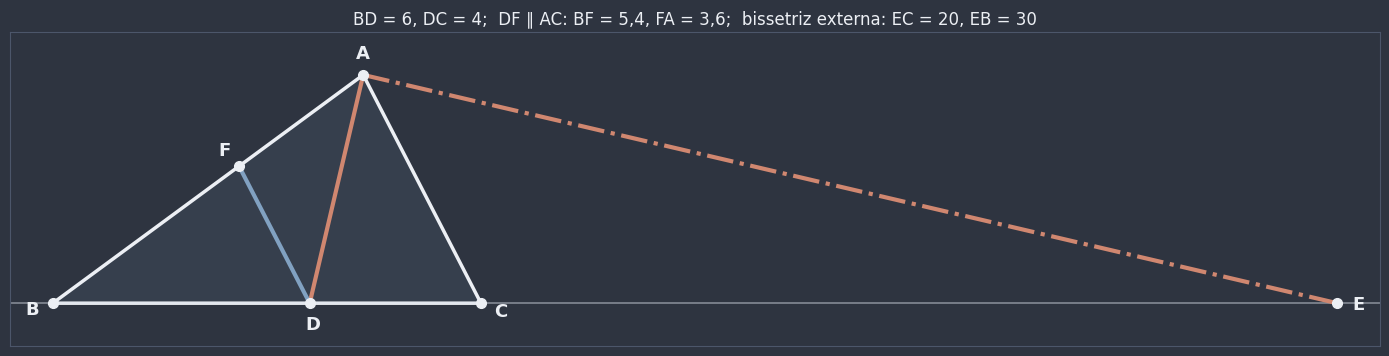

In [7]:
x_A = 145 / 20
A, B, C = np.array([x_A, math.sqrt(81 - x_A**2)]), np.array([0.0, 0.0]), np.array([10.0, 0.0])
D = pe_da_bissetriz(A, B, C)
F = cruzamento(D, direcao_de(A, C), A, direcao_de(A, B))  # a paralela a AC por D, cortando AB
E = pe_da_bissetriz_externa(A, B, C)
print(f"AB = {math.dist(A, B):.4f}, AC = {math.dist(A, C):.4f}, BC = {math.dist(B, C):.4f}")
print(f"BD = {math.dist(B, D):.4f}, DC = {math.dist(D, C):.4f}")
print(f"BF = {math.dist(B, F):.4f}, FA = {math.dist(F, A):.4f}")
print(f"EC = {math.dist(E, C):.4f}, EB = {math.dist(E, B):.4f}")

fig, ax = plt.subplots(figsize=(14, 5.5))
fig.patch.set_facecolor(NORD_FUNDO)
preparar_eixo(ax, [A, B, C, E], margem=1.0)
desenhar_reta(ax, B, C, cor=COR_TRANSVERSAL, largura=1.2, alpha=0.5)
ax.add_patch(Polygon([A, B, C], closed=True, facecolor=COR_PARALELA, alpha=0.1, edgecolor="none"))
ax.add_patch(Polygon([A, B, C], closed=True, fill=False, edgecolor=NORD_TEXTO, lw=2.5))
desenhar_segmento(ax, A, D, cor=COR_BISSETRIZ, largura=3)
desenhar_segmento(ax, A, E, cor=COR_BISSETRIZ, largura=3, estilo="-.")
desenhar_segmento(ax, D, F, cor=COR_PARALELA, largura=3)
centro = (A + B + C) / 3
for X, nome in ((A, "A"), (B, "B"), (C, "C"), (D, "D"), (E, "E"), (F, "F")):
    desenhar_ponto(ax, X, cor=NORD_TEXTO)
    rotular_fora(ax, X, nome, centro if nome != "A" else (A[0], 0), distancia=0.5, tamanho=13)
ax.set_title("BD = 6, DC = 4;  DF ∥ AC: BF = 5,4, FA = 3,6;  bissetriz externa: EC = 20, EB = 30", color=NORD_TEXTO,
             fontsize=12)
plt.tight_layout()
plt.show()

## Desafio

**Exercício 6.** A demonstração do 2 : 1 do baricentro, verificada passo a passo.

In [8]:
def cadeia_do_baricentro(A, B, C) -> dict:
    """Constrói N, M, G, P e Q como no enunciado e devolve tudo o que a demonstração usa."""
    N, M = ponto_medio(A, B), ponto_medio(A, C)
    G = cruzamento_das_retas(B, M, C, N)  # o cruzamento das medianas BM e CN
    P, Q = ponto_medio(B, G), ponto_medio(C, G)
    return {"N": N, "M": M, "G": G, "P": P, "Q": Q}


A_ex6, B_ex6, C_ex6 = np.array([1.0, 6.0]), np.array([0.0, 0.0]), np.array([8.0, 1.0])
pts = cadeia_do_baricentro(A_ex6, B_ex6, C_ex6)
N, M, G, P, Q = (pts[k] for k in "NMGPQ")
BC = math.dist(B_ex6, C_ex6)

# Passos 1 e 2: as duas bases médias
NM_BC_ex6 = math.dist(N, M) / BC
PQ_BC_ex6 = math.dist(P, Q) / BC
paralelos_ex6 = (sao_paralelos(N, M, B_ex6, C_ex6), sao_paralelos(P, Q, B_ex6, C_ex6))
# Passos 3 e 4: NMQP é paralelogramo, e as diagonais MP e NQ se cortam ao meio (em G)
meio_MP_ex6 = ponto_medio(M, P)
meio_NQ_ex6 = ponto_medio(N, Q)
# Conclusão: BG = BP + PG = 2·GM
razao_ex6 = math.dist(B_ex6, G) / math.dist(G, M)

# (b) A mesma cadeia em 100 triângulos sorteados
gerador_ex6 = np.random.default_rng(10)
erros = []
for _ in range(100):
    A_s, B_s, C_s = gerador_ex6.uniform(-5, 5, (3, 2))
    pts_s = cadeia_do_baricentro(A_s, B_s, C_s)
    erros.append(abs(math.dist(B_s, pts_s["G"]) / math.dist(pts_s["G"], pts_s["M"]) - 2))
maior_erro_ex6 = max(erros)

print(NM_BC_ex6, PQ_BC_ex6, paralelos_ex6, meio_MP_ex6, meio_NQ_ex6, G, razao_ex6, maior_erro_ex6)

0.5 0.5 (np.True_, np.True_) [3.         2.33333333] [3.         2.33333333] [3.         2.33333333] 2.0000000000000004 3.992361996552063e-13


A figura mostra a cadeia: as duas bases médias ($\overline{NM}$ e $\overline{PQ}$, paralelas a $\overline{BC}$ e com metade do seu comprimento), o paralelogramo $NMQP$ e as suas diagonais cortando-se em $G$. Os três pedaços marcados com um tracinho, $\overline{BP}$, $\overline{PG}$ e $\overline{GM}$, são congruentes: é o 2 : 1.

📎 Em [`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb), a razão 2 : 1 saiu de uma conta com coordenadas ($G = \frac{A + B + C}{3}$). Aqui ela sai **só de geometria**: bases médias, paralelogramo e diagonais. Repare que nenhuma das duas provas usa semelhança.

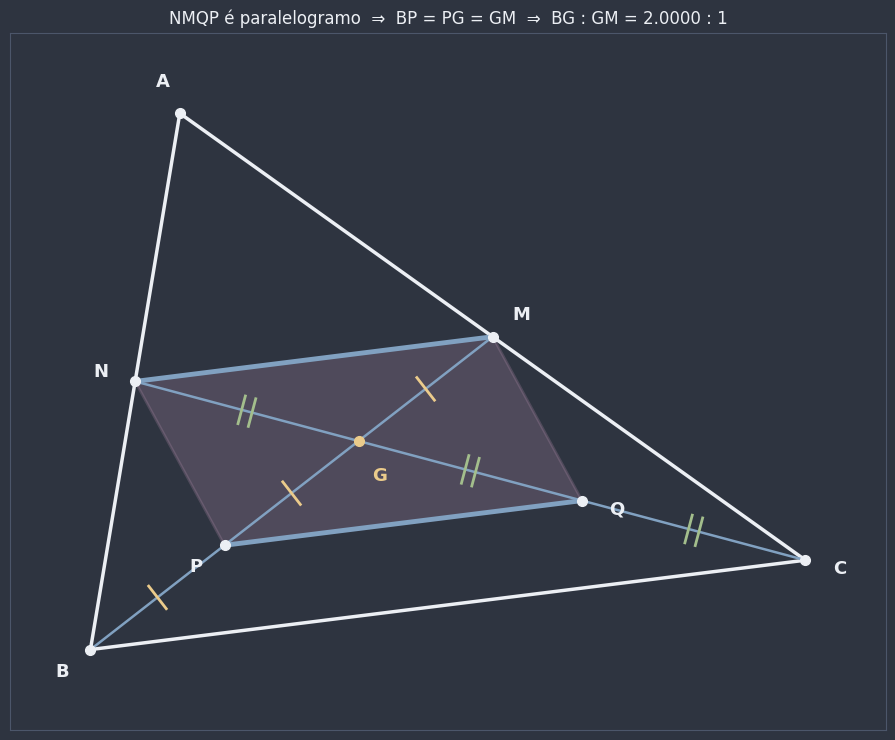

In [9]:
fig, ax = plt.subplots(figsize=(10, 7.5))
fig.patch.set_facecolor(NORD_FUNDO)
preparar_eixo(ax, [A_ex6, B_ex6, C_ex6], margem=0.9)
ax.add_patch(Polygon([A_ex6, B_ex6, C_ex6], closed=True, fill=False, edgecolor=NORD_TEXTO, lw=2.5))
ax.add_patch(Polygon([N, M, Q, P], closed=True, facecolor=COR_EXTRA, alpha=0.25, edgecolor=COR_EXTRA, lw=2))
desenhar_segmento(ax, B_ex6, M, cor=COR_SECUNDARIA, largura=1.8)
desenhar_segmento(ax, C_ex6, N, cor=COR_SECUNDARIA, largura=1.8)
desenhar_segmento(ax, N, M, cor=COR_PARALELA, largura=3.5)
desenhar_segmento(ax, P, Q, cor=COR_PARALELA, largura=3.5)
for X, Y in ((B_ex6, P), (P, G), (G, M)):
    marcar_congruentes(ax, X, Y, tracos=1, cor=COR_AVISO)
for X, Y in ((C_ex6, Q), (Q, G), (G, N)):
    marcar_congruentes(ax, X, Y, tracos=2, cor=COR_DESTAQUE)
centro = G
for X, nome in ((A_ex6, "A"), (B_ex6, "B"), (C_ex6, "C"), (N, "N"), (M, "M"), (P, "P"), (Q, "Q")):
    desenhar_ponto(ax, X, cor=NORD_TEXTO)
    rotular_fora(ax, X, nome, centro, distancia=0.4, tamanho=13)
desenhar_ponto(ax, G, cor=COR_AVISO)
ax.text(G[0] + 0.15, G[1] - 0.45, "G", color=COR_AVISO, fontsize=13, fontweight="bold")
ax.set_title(f"NMQP é paralelogramo  ⇒  BP = PG = GM  ⇒  BG : GM = {razao_ex6:.4f} : 1", color=NORD_TEXTO,
             fontsize=12)
plt.tight_layout()
plt.show()

**Exercício 7.** A circunferência de Apolônio, caçada numa grade de pontos.

In [10]:
A_ex7, B_ex7, k_ex7 = np.array([0.0, 0.0]), np.array([6.0, 0.0]), 2

# (a) D divide AB por dentro na razão 2 : 1; E divide por fora, com λ = k/(k − 1) = 2.
D_ex7 = divide_segmento(A_ex7, B_ex7, 2, 1)  # (4, 0): DA/DB = 4/2 = 2
E_ex7 = A_ex7 + k_ex7 / (k_ex7 - 1) * (B_ex7 - A_ex7)  # (12, 0): EA/EB = 12/6 = 2

# (b) A circunferência de diâmetro DE
centro_ex7 = ponto_medio(D_ex7, E_ex7)  # (8, 0)
raio_ex7 = math.dist(D_ex7, E_ex7) / 2  # 4

# (c) Força bruta na grade
pontos_ex7 = []
for x in np.linspace(-2, 14, 161):
    for y in np.linspace(-6, 6, 121):
        P = np.array([x, y])
        if math.dist(P, B_ex7) < 1e-9:
            continue  # em B, a razão não está definida (divisão por zero)
        if abs(math.dist(P, A_ex7) / math.dist(P, B_ex7) - 2) < 0.02:
            pontos_ex7.append(P)

# (d) Quão longe da circunferência ficaram os pontos encontrados?
maior_desvio_ex7 = max(abs(math.dist(P, centro_ex7) - raio_ex7) for P in pontos_ex7)

print(D_ex7, E_ex7, centro_ex7, raio_ex7, len(pontos_ex7), maior_desvio_ex7)

[4. 0.] [12.  0.] [8. 0.] 4.0 338 0.11946598480919768


Os pontos da grade só **quase** satisfazem $PA/PB = 2$ (a tolerância de 0,02 forma uma "faixa" em volta da curva), por isso o desvio não é zero, mas fica pequeno. Diminuindo a tolerância e refinando a grade, o desvio vai a zero. A figura confirma: todos os pontos caçados caem sobre a circunferência de diâmetro $\overline{DE}$.

🎯 **Para que serve:** a circunferência de Apolônio aparece em problemas de **perseguição**. Se um barco $A$ é duas vezes mais rápido que um barco $B$, os pontos que os dois alcançam no mesmo instante são aqueles que estão duas vezes mais longe de $A$ do que de $B$: exatamente a circunferência de Apolônio com $k = 2$. Se $B$ quiser fugir, precisa sair dessa circunferência antes de ser alcançado.

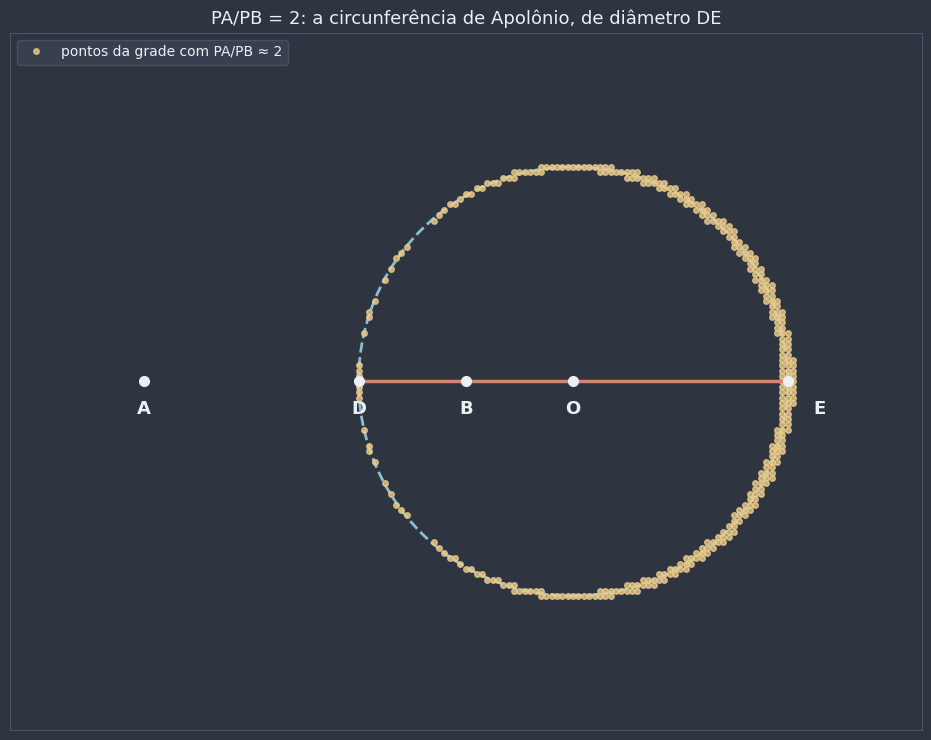

In [11]:
fig, ax = plt.subplots(figsize=(11, 7.5))
fig.patch.set_facecolor(NORD_FUNDO)
preparar_eixo(ax, [(-2, -6), (14, 6)], margem=0.5)
desenhar_circunferencia(ax, centro_ex7, raio_ex7, cor=COR_PONTO, largura=2, estilo="--")
xs, ys = zip(*pontos_ex7)
ax.plot(xs, ys, "o", color=COR_AVISO, markersize=4, alpha=0.8, zorder=4, label="pontos da grade com PA/PB ≈ 2")
desenhar_segmento(ax, D_ex7, E_ex7, cor=COR_BISSETRIZ, largura=2.5)
for X, nome in ((A_ex7, "A"), (B_ex7, "B"), (D_ex7, "D"), (E_ex7, "E"), (centro_ex7, "O")):
    desenhar_ponto(ax, X, cor=NORD_TEXTO)
    ax.text(X[0] + (0.6 if nome == "E" else 0), X[1] - 0.6, nome, color=NORD_TEXTO, fontsize=13, fontweight="bold", ha="center")
legenda = ax.legend(loc="upper left", facecolor=NORD_PAINEL, edgecolor=NORD_LINHA)
for texto in legenda.get_texts():
    texto.set_color(NORD_TEXTO)
ax.set_title("PA/PB = 2: a circunferência de Apolônio, de diâmetro DE", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()